# Corpus Metrics Analysis

This notebook computes and compares metrics across the three bilingual translation datasets:
- **WikiText-103** — Encyclopedia articles
- **FEVER** — Factual Wikipedia passages  
- **Europarl** — European Parliament debates

Each section computes one category of metrics, displays results per dataset, and finishes with a comparative table.

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from pathlib import Path

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from metrics.loader import load_dataset, find_latest_output, tokenize_simple, sentence_split
from metrics.general_metrics import compute_general_metrics, compute_frequency_metrics
from metrics.lexical_metrics import compute_lexical_metrics
from metrics.syntactic_metrics import compute_syntactic_metrics
from metrics.quality_metrics import compute_quality_metrics

pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['figure.dpi'] = 100

GRAPHICS_DIR = Path('../figures')
GRAPHICS_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = ['wikitext', 'fever', 'europarl']
LABELS = {'wikitext': 'WikiText', 'fever': 'FEVER', 'europarl': 'Europarl'}

print("Libraries loaded.")

Libraries loaded.


## Load all datasets

In [4]:
data = {}
for ds in DATASETS:
    path = find_latest_output(ds)
    data[ds] = load_dataset(ds, path)
    n = data[ds]['total_entries']
    print(f"  {LABELS[ds]:>10}: {n:,} entries from {path.name}")

# Pre-extract text lists for convenience
en_texts = {ds: [e['en_text'] for e in data[ds]['entries']] for ds in DATASETS}
es_texts = {ds: [e['es_text'] for e in data[ds]['entries']] for ds in DATASETS}
print("\nAll datasets loaded.")

    WikiText: 1,000 entries from wikitext-103-raw.wiki.train.selected_1000_260620_235838.json
       FEVER: 9,998 entries from fever_selected_260712_212751.json
    Europarl: 1,005 entries from selected_260710_084528.json

All datasets loaded.


---
## 1. General Corpus Metrics

Basic descriptive statistics: words, types, characters, words/document, sentences/document.

In [3]:
general = {}
for ds in DATASETS:
    general[ds] = {
        'en': compute_general_metrics(en_texts[ds], 'en'),
        'es': compute_general_metrics(es_texts[ds], 'es'),
    }
    print(f"  {LABELS[ds]} done.")

# Build comparison table
rows = []
for ds in DATASETS:
    for lang in ['en', 'es']:
        g = general[ds][lang]
        rows.append({
            'Dataset': LABELS[ds],
            'Lang': lang.upper(),
            'Documents': g['num_documents'],
            'Total Words': g['total_tokens'],
            'Unique Types': g['unique_types'],
            'Total Chars': g['total_characters'],
            'Words/Doc (mean)': g['words_per_document']['mean'],
            'Words/Doc (median)': g['words_per_document']['median'],
            'Words/Doc (std)': g['words_per_document']['std'],
            'Words/Doc (min)': g['words_per_document']['min'],
            'Words/Doc (max)': g['words_per_document']['max'],
            'Sents/Doc (mean)': g['sentences_per_document']['mean'],
        })

df_general = pd.DataFrame(rows)
df_general

  WikiText done.
  FEVER done.
  Europarl done.


,Dataset,Lang,Documents,Total Words,Unique Types,Total Chars,Words/Doc (mean),Words/Doc (median),Words/Doc (std),Words/Doc (min),Words/Doc (max),Sents/Doc (mean)
0,WikiText,EN,1000,2855853,84029,17634690,"2,855.90","2,247.00","1,750.10",807,8571,129.70
1,WikiText,ES,1000,3037875,105266,18427292,"3,037.90","2,409.00","1,875.50",872,9438,127.60
2,FEVER,EN,9998,1753860,54087,10527617,175.40,139.50,114.80,76,3554,8.20
3,FEVER,ES,9998,1941463,63259,11443988,194.20,156.00,122.60,71,3701,8.00
4,Europarl,EN,1005,6950546,36790,41538682,"6,916.00","5,886.00","5,673.10",217,25619,276.50
5,Europarl,ES,1005,6954048,57701,43695445,"6,919.50","5,898.00","5,658.80",199,26145,278.20


### Word count distributions per dataset

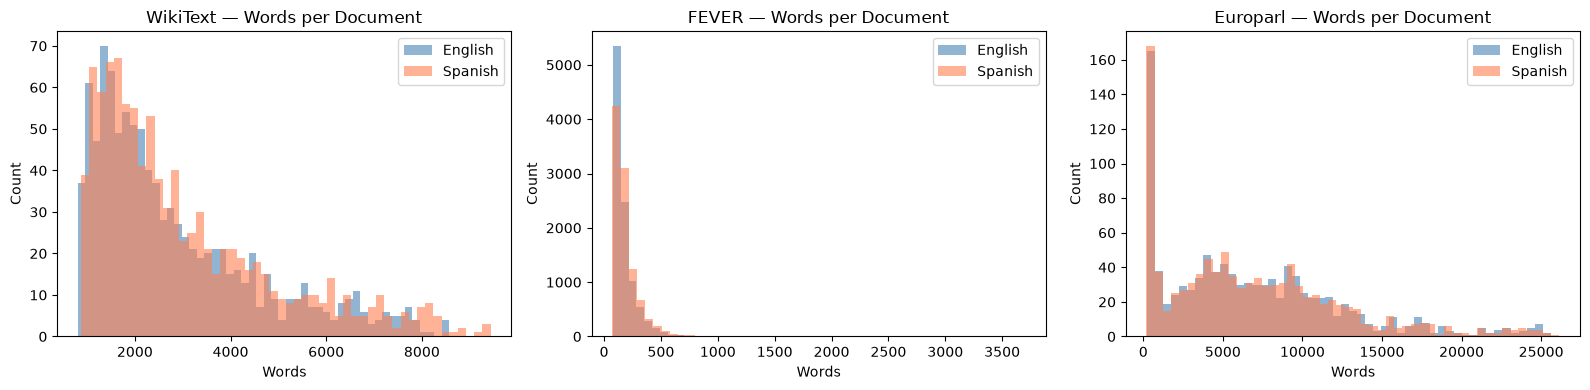

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ds in enumerate(DATASETS):
    en_wc = general[ds]['en']['distribution_word_counts']
    es_wc = general[ds]['es']['distribution_word_counts']
    axes[i].hist(en_wc, bins=50, alpha=0.6, label='English', color='steelblue')
    axes[i].hist(es_wc, bins=50, alpha=0.6, label='Spanish', color='coral')
    axes[i].set_title(f'{LABELS[ds]} — Words per Document')
    axes[i].set_xlabel('Words')
    axes[i].set_ylabel('Count')
    axes[i].legend()
plt.tight_layout()
plt.show()

---
## 2. Word Frequency Metrics

Zipf distribution, hapax/dis legomena, vocabulary coverage, and growth curve.

In [5]:
frequency = {}
for ds in DATASETS:
    frequency[ds] = {
        'en': compute_frequency_metrics(en_texts[ds], 'en'),
        'es': compute_frequency_metrics(es_texts[ds], 'es'),
    }
    print(f"  {LABELS[ds]} done.")

# Comparison table
rows = []
for ds in DATASETS:
    for lang in ['en', 'es']:
        f = frequency[ds][lang]
        rows.append({
            'Dataset': LABELS[ds],
            'Lang': lang.upper(),
            'Zipf Exponent': f['zipf_exponent'],
            'Hapax': f'{f["hapax_legomena"]:,}',
            'Hapax %': f['hapax_legomena_pct'],
            'Dis Legomena': f'{f["dis_legomena"]:,}',
            'Dis %': f['dis_legomena_pct'],
            'Top-100 Coverage %': f['vocabulary_coverage_by_top_n'].get('100', '-'),
            'Top-1000 Coverage %': f['vocabulary_coverage_by_top_n'].get('1000', '-'),
        })

df_freq = pd.DataFrame(rows)
df_freq

  WikiText done.
  FEVER done.
  Europarl done.


,Dataset,Lang,Zipf Exponent,Hapax,Hapax %,Dis Legomena,Dis %,Top-100 Coverage %,Top-1000 Coverage %
0,WikiText,EN,0.90,"33,380",39.72,"11,832",14.08,42.17,64.66
1,WikiText,ES,0.95,"42,093",39.99,"15,258",14.49,45.19,63.72
2,FEVER,EN,0.93,"23,975",44.33,"7,856",14.52,46.84,73.51
3,FEVER,ES,0.95,"27,778",43.91,"9,330",14.75,50.03,73.29
4,Europarl,EN,0.98,"10,534",28.63,"4,126",11.22,53.77,80.90
5,Europarl,ES,0.96,"18,313",31.74,"7,098",12.30,52.53,77.72


### Zipf Distribution (log-log plot)

A straight line with slope ~1.0 confirms natural language behavior.

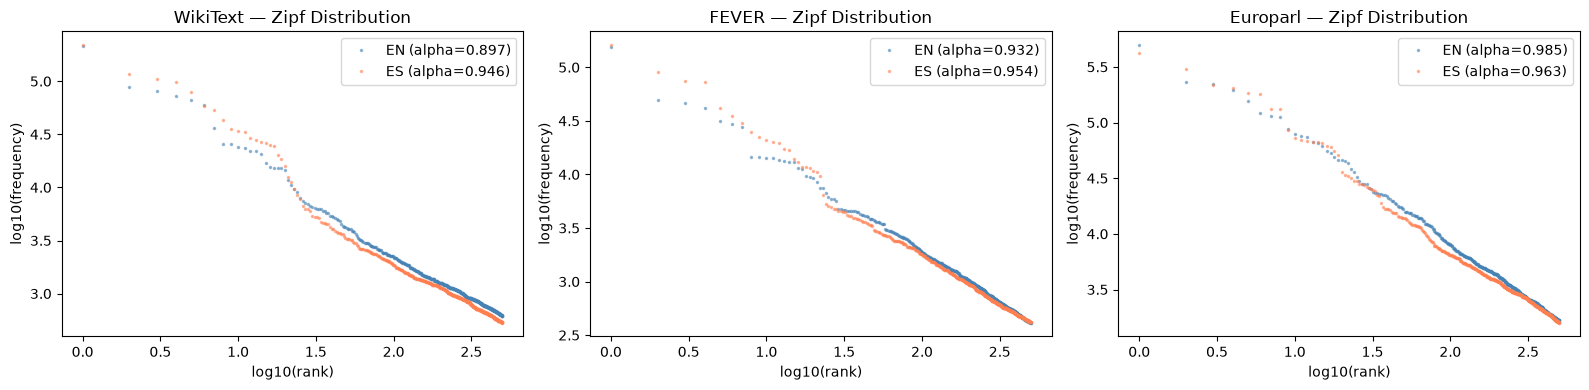

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ds in enumerate(DATASETS):
    for lang, color in [('en', 'steelblue'), ('es', 'coral')]:
        z = frequency[ds][lang]['zipf_distribution']
        ranks = [p['log_rank'] for p in z]
        freqs = [p['log_freq'] for p in z]
        alpha = frequency[ds][lang]['zipf_exponent']
        axes[i].plot(ranks, freqs, '.', color=color, alpha=0.5, markersize=3,
                     label=f'{lang.upper()} (alpha={alpha})')
    axes[i].set_title(f'{LABELS[ds]} — Zipf Distribution')
    axes[i].set_xlabel('log10(rank)')
    axes[i].set_ylabel('log10(frequency)')
    axes[i].legend()
plt.tight_layout()
plt.show()

### Vocabulary Growth Curve

How the number of unique types grows as words accumulate.

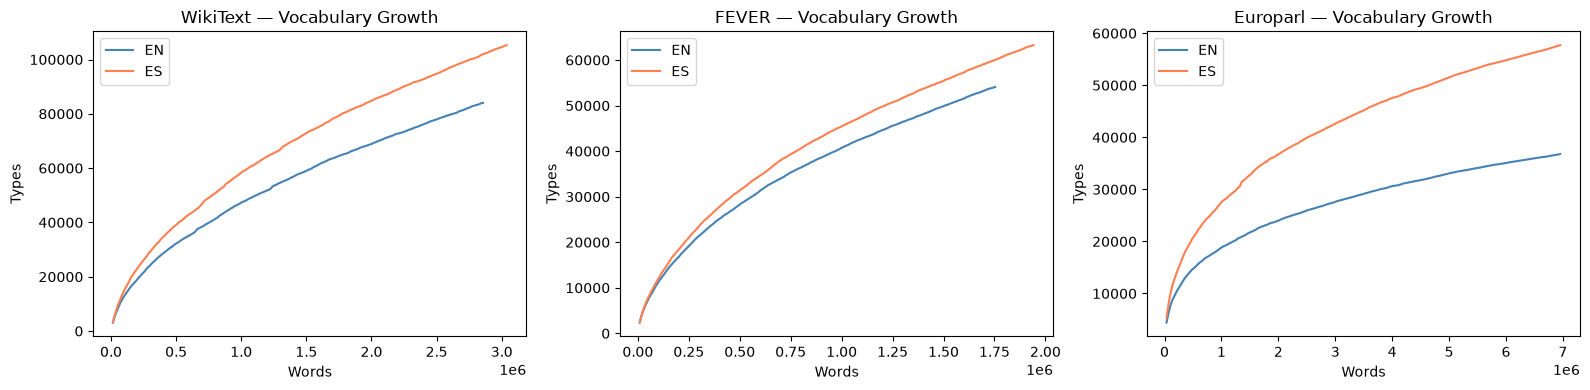

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ds in enumerate(DATASETS):
    for lang, color in [('en', 'steelblue'), ('es', 'coral')]:
        gc = frequency[ds][lang]['vocabulary_growth_curve']
        words = [p['tokens'] for p in gc]
        types = [p['types'] for p in gc]
        axes[i].plot(words, types, color=color, linewidth=1.5, label=lang.upper())
    axes[i].set_title(f'{LABELS[ds]} — Vocabulary Growth')
    axes[i].set_xlabel('Words')
    axes[i].set_ylabel('Types')
    axes[i].legend()
plt.tight_layout()
plt.show()

---
## 3. Lexical Diversity Metrics

TTR, RTTR, CTTR, MATTR (window=100), and MTLD.

In [8]:
lexical = {}
for ds in DATASETS:
    lexical[ds] = {
        'en': compute_lexical_metrics(en_texts[ds], 'en'),
        'es': compute_lexical_metrics(es_texts[ds], 'es'),
    }
    print(f"  {LABELS[ds]} done.")

# Comparison table
rows = []
for ds in DATASETS:
    for lang in ['en', 'es']:
        c = lexical[ds][lang]['corpus_level']
        p = lexical[ds][lang]['per_document_averages']
        rows.append({
            'Dataset': LABELS[ds],
            'Lang': lang.upper(),
            'Vocab Size': f'{c["vocabulary_size"]:,}',
            'TTR (corpus)': c['ttr'],
            'RTTR': c['rttr'],
            'CTTR': c['cttr'],
            'MATTR (w=100)': c['mattr_w100'],
            'MTLD': c['mtld'],
            'MATTR/doc (mean)': p['mattr_mean'],
            'MTLD/doc (mean)': p['mtld_mean'],
        })

df_lex = pd.DataFrame(rows)
df_lex

  WikiText done.
  FEVER done.
  Europarl done.


,Dataset,Lang,Vocab Size,TTR (corpus),RTTR,CTTR,MATTR (w=100),MTLD,MATTR/doc (mean),MTLD/doc (mean)
0,WikiText,EN,"84,029",0.03,49.72,35.16,0.71,84.63,0.71,84.69
1,WikiText,ES,"105,266",0.03,60.40,42.71,0.69,77.33,0.69,77.91
2,FEVER,EN,"54,087",0.03,40.84,28.88,0.69,72.85,0.68,68.44
3,FEVER,ES,"63,259",0.03,45.40,32.10,0.67,63.24,0.66,61.19
4,Europarl,EN,"36,790",0.01,13.95,9.87,0.71,89.74,0.71,89.29
5,Europarl,ES,"57,701",0.01,21.88,15.47,0.72,91.47,0.72,91.54


### MATTR and MTLD distributions per document

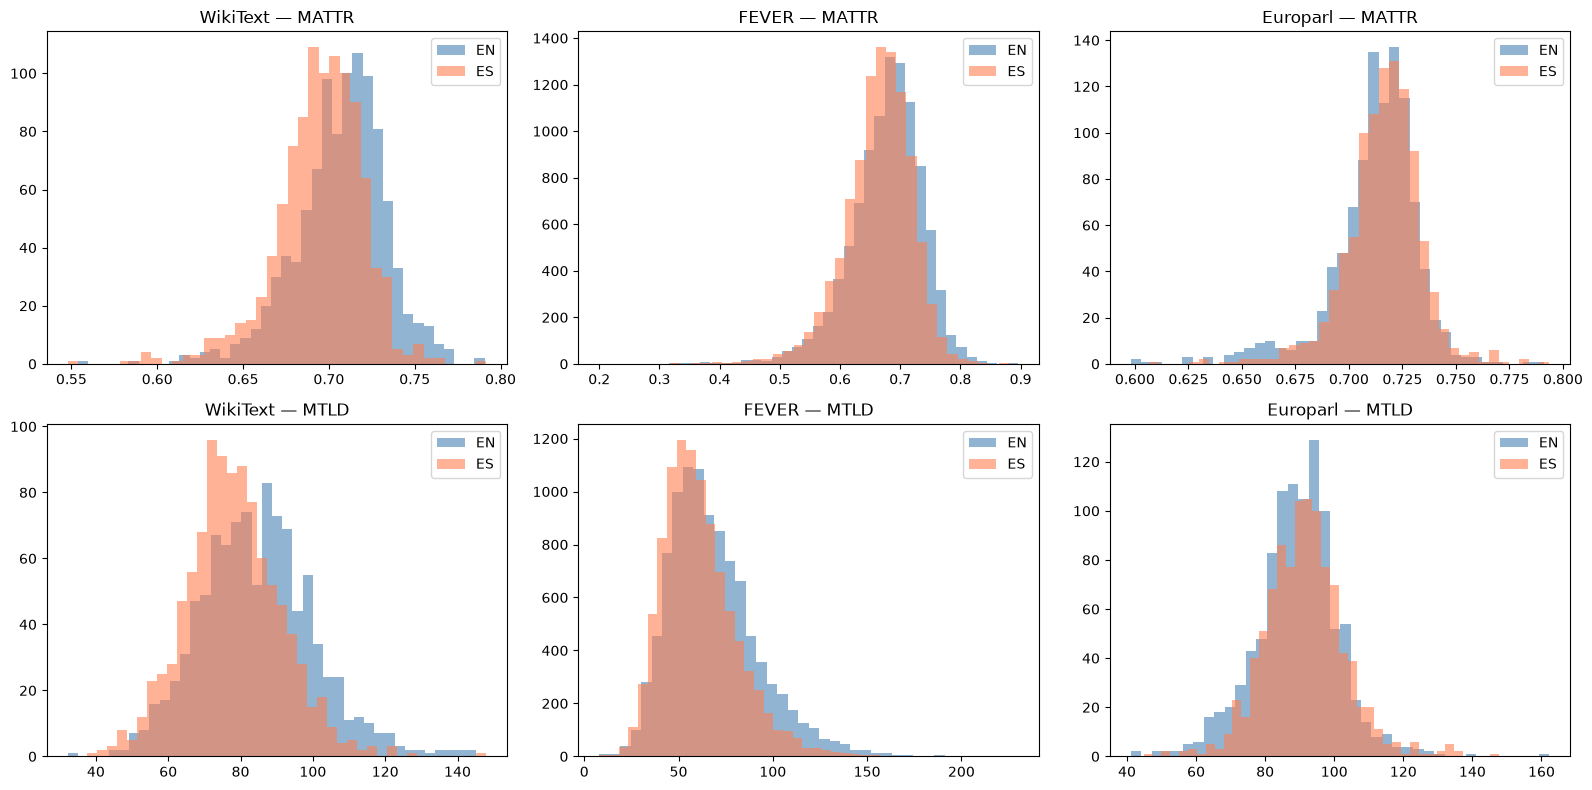

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, ds in enumerate(DATASETS):
    # MATTR
    en_mattr = lexical[ds]['en']['distribution_mattr']
    es_mattr = lexical[ds]['es']['distribution_mattr']
    axes[0][i].hist(en_mattr, bins=40, alpha=0.6, label='EN', color='steelblue')
    axes[0][i].hist(es_mattr, bins=40, alpha=0.6, label='ES', color='coral')
    axes[0][i].set_title(f'{LABELS[ds]} — MATTR')
    axes[0][i].legend()

    # MTLD
    en_mtld = lexical[ds]['en']['distribution_mtld']
    es_mtld = lexical[ds]['es']['distribution_mtld']
    axes[1][i].hist(en_mtld, bins=40, alpha=0.6, label='EN', color='steelblue')
    axes[1][i].hist(es_mtld, bins=40, alpha=0.6, label='ES', color='coral')
    axes[1][i].set_title(f'{LABELS[ds]} — MTLD')
    axes[1][i].legend()

plt.tight_layout()
plt.show()

---
## 4. Syntactic Metrics

Sentence length distribution and POS tagging (requires spaCy).

In [10]:
syntactic = {}
for ds in DATASETS:
    syntactic[ds] = {
        'en': compute_syntactic_metrics(en_texts[ds], 'en'),
        'es': compute_syntactic_metrics(es_texts[ds], 'es'),
    }
    print(f"  {LABELS[ds]} done.")

# Sentence length comparison
rows = []
for ds in DATASETS:
    for lang in ['en', 'es']:
        s = syntactic[ds][lang]['sentence_length']
        rows.append({
            'Dataset': LABELS[ds],
            'Lang': lang.upper(),
            'Sent Len (mean)': s['mean'],
            'Sent Len (median)': s['median'],
            'Sent Len (std)': s['std'],
            'Sent Len (min)': s['min'],
            'Sent Len (max)': s['max'],
        })

df_synt = pd.DataFrame(rows)
df_synt

  Computing POS distribution (en)...
  Computing POS distribution (es)...
  WikiText done.
  Computing POS distribution (en)...
  Computing POS distribution (es)...
  FEVER done.
  Computing POS distribution (en)...
  Computing POS distribution (es)...
  Europarl done.


,Dataset,Lang,Sent Len (mean),Sent Len (median),Sent Len (std),Sent Len (min),Sent Len (max)
0,WikiText,EN,22.00,21.00,11.90,0,403
1,WikiText,ES,23.80,22.00,12.90,0,501
2,FEVER,EN,21.40,20.00,12.80,0,469
3,FEVER,ES,24.40,22.00,14.40,0,658
4,Europarl,EN,25.00,22.00,15.20,0,1584
5,Europarl,ES,24.90,22.00,15.20,0,1616


### Sentence length distributions

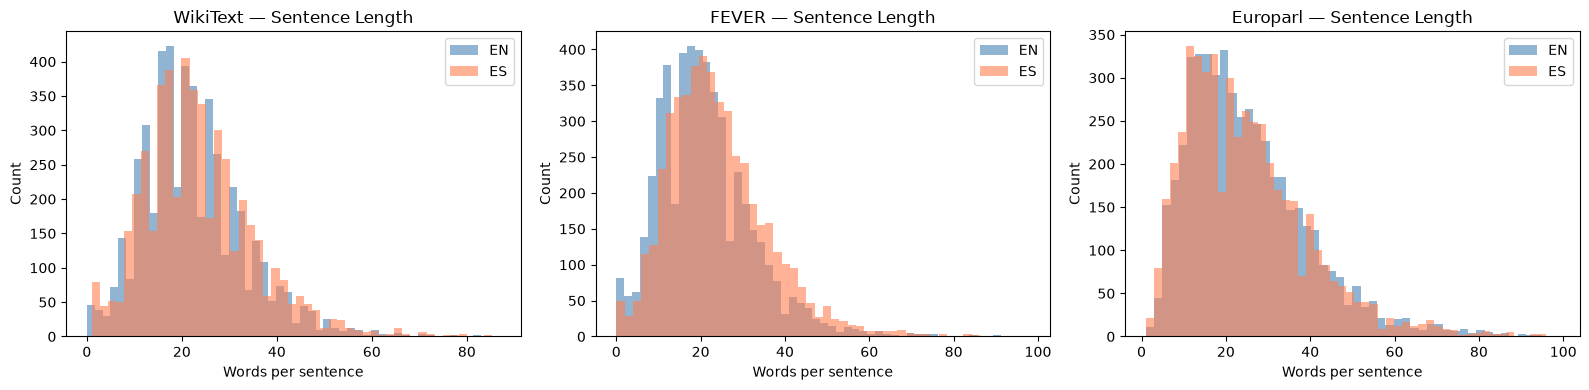

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ds in enumerate(DATASETS):
    en_sl = syntactic[ds]['en']['distribution_sentence_lengths']
    es_sl = syntactic[ds]['es']['distribution_sentence_lengths']
    # Cap at 100 words for readable histograms
    en_sl_cap = [x for x in en_sl if x <= 100]
    es_sl_cap = [x for x in es_sl if x <= 100]
    axes[i].hist(en_sl_cap, bins=50, alpha=0.6, label='EN', color='steelblue')
    axes[i].hist(es_sl_cap, bins=50, alpha=0.6, label='ES', color='coral')
    axes[i].set_title(f'{LABELS[ds]} — Sentence Length')
    axes[i].set_xlabel('Words per sentence')
    axes[i].set_ylabel('Count')
    axes[i].legend()
plt.tight_layout()
plt.show()

### POS Distribution (if spaCy is available)

In [12]:
# Show POS distribution if available (requires spaCy)
for ds in DATASETS:
    pos_en = syntactic[ds]['en'].get('pos_distribution')
    pos_es = syntactic[ds]['es'].get('pos_distribution')
    if pos_en and pos_es:
        all_tags = sorted(set(list(pos_en.keys()) + list(pos_es.keys())))
        rows_pos = []
        for tag in all_tags:
            rows_pos.append({
                'POS': tag,
                'EN %': pos_en.get(tag, {}).get('percentage', 0),
                'ES %': pos_es.get(tag, {}).get('percentage', 0),
            })
        df_pos = pd.DataFrame(rows_pos)
        print(f"\n{LABELS[ds]} — POS Distribution:")
        display(df_pos)
    else:
        print(f"\n{LABELS[ds]}: POS not available (install spaCy + models)")


WikiText — POS Distribution:


,POS,EN %,ES %
0,ADJ,6.89,7.89
1,ADP,13.85,18.98
2,ADV,2.57,2.46
3,AUX,3.80,2.50
4,CCONJ,3.43,3.30
5,DET,10.33,13.47
6,INTJ,0.03,0.01
7,NOUN,20.08,20.43
8,NUM,4.22,2.81
9,PART,1.73,0.01



FEVER — POS Distribution:


,POS,EN %,ES %
0,ADJ,6.20,6.99
1,ADP,12.73,19.98
2,ADV,2.20,2.02
3,AUX,3.62,2.25
4,CCONJ,2.73,2.62
5,DET,11.56,14.69
6,INTJ,0.08,0.01
7,NOUN,18.12,19.11
8,NUM,7.12,4.58
9,PART,1.54,0.01



Europarl — POS Distribution:


,POS,EN %,ES %
0,ADJ,6.96,8.38
1,ADP,12.79,16.89
2,ADV,3.26,3.04
3,AUX,5.40,3.38
4,CCONJ,3.12,3.03
5,DET,11.00,14.60
6,INTJ,0.04,0.02
7,NOUN,19.29,21.16
8,NUM,1.73,1.81
9,PART,2.46,0.05


---
## 5. Quality & Semantic Metrics

Expansion ratio, duplicates, near-duplicates, stopwords, special characters, NER, classification distribution.

In [13]:
quality = {}
for ds in DATASETS:
    quality[ds] = compute_quality_metrics(data[ds]['entries'])
    print(f"  {LABELS[ds]} done.")

# Quality comparison table
rows = []
for ds in DATASETS:
    q = quality[ds]
    rows.append({
        'Dataset': LABELS[ds],
        'Expansion (mean)': q['expansion_ratio_en_es']['mean'],
        'Expansion (median)': q['expansion_ratio_en_es']['median'],
        'Expansion (std)': q['expansion_ratio_en_es']['std'],
        'Exact Dupes EN': q['duplicates']['exact_en'],
        'Exact Dupes ES': q['duplicates']['exact_es'],
        'Near-Dupes EN': q['duplicates']['near_duplicate_pairs_en'],
        'Near-Dupes ES': q['duplicates']['near_duplicate_pairs_es'],
        'Stopwords EN %': q['stopword_pct']['en'],
        'Stopwords ES %': q['stopword_pct']['es'],
        'Special Chars EN %': q['special_characters_pct']['en_mean'],
        'Special Chars ES %': q['special_characters_pct']['es_mean'],
        'Uppercase EN %': q['uppercase_pct']['en_mean'],
        'Uppercase ES %': q['uppercase_pct']['es_mean'],
    })

df_quality = pd.DataFrame(rows)
df_quality

  Computing NER (en)...
  Computing NER (es)...
  WikiText done.
  Computing NER (en)...
  Computing NER (es)...
  FEVER done.
  Computing NER (en)...
  Computing NER (es)...
  Europarl done.


,Dataset,Expansion (mean),Expansion (median),Expansion (std),Exact Dupes EN,Exact Dupes ES,Near-Dupes EN,Near-Dupes ES,Stopwords EN %,Stopwords ES %,Special Chars EN %,Special Chars ES %,Uppercase EN %,Uppercase ES %
0,WikiText,1.04,1.04,0.04,0,0,0,0,36.67,38.59,3.08,2.47,3.56,3.16
1,FEVER,1.09,1.09,0.07,11,0,0,0,33.16,38.89,3.24,2.44,5.66,4.15
2,Europarl,1.05,1.05,0.02,0,0,0,0,43.16,40.68,3.23,3.05,4.51,3.98


### Expansion Ratio Distribution (EN to ES)

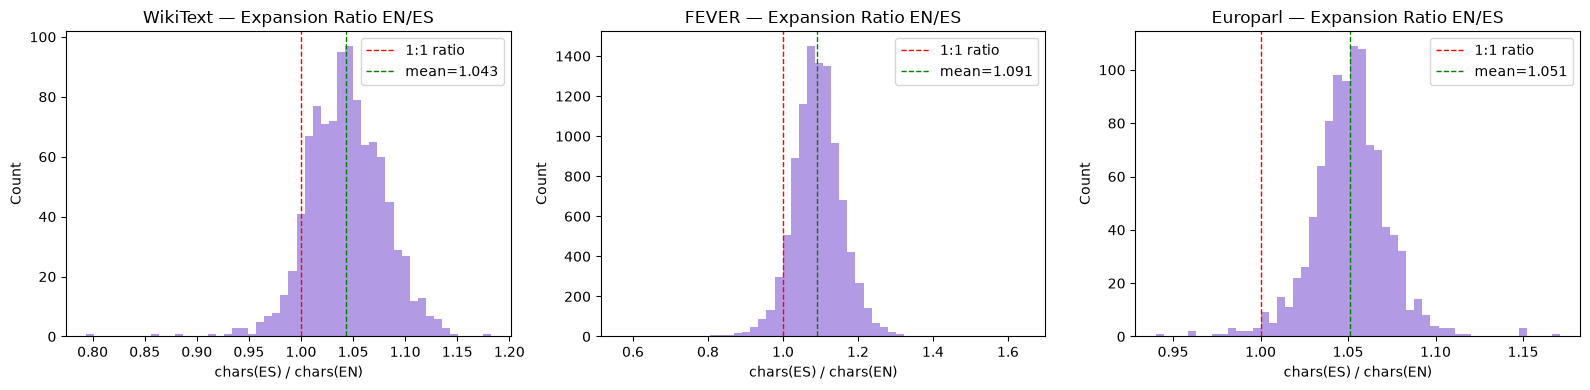

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ds in enumerate(DATASETS):
    ratios = quality[ds]['expansion_ratio_en_es']['distribution']
    axes[i].hist(ratios, bins=50, color='mediumpurple', alpha=0.7)
    axes[i].axvline(x=1.0, color='red', linestyle='--', linewidth=1, label='1:1 ratio')
    mean_r = quality[ds]['expansion_ratio_en_es']['mean']
    axes[i].axvline(x=mean_r, color='green', linestyle='--', linewidth=1, label=f'mean={mean_r:.3f}')
    axes[i].set_title(f'{LABELS[ds]} — Expansion Ratio EN/ES')
    axes[i].set_xlabel('chars(ES) / chars(EN)')
    axes[i].set_ylabel('Count')
    axes[i].legend()
plt.tight_layout()
plt.show()

### Classification Distribution per Dataset

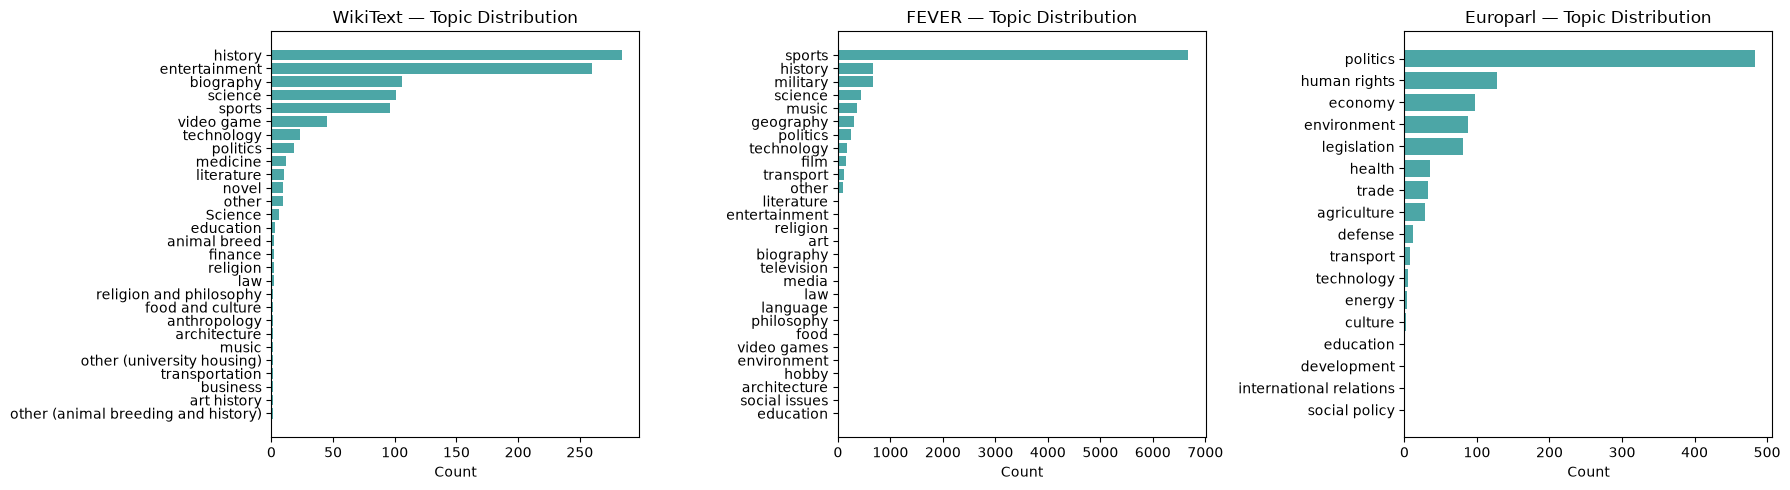

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, ds in enumerate(DATASETS):
    dist = quality[ds]['classification_distribution']
    categories = list(dist.keys())
    counts = list(dist.values())
    axes[i].barh(categories, counts, color='teal', alpha=0.7)
    axes[i].set_title(f'{LABELS[ds]} — Topic Distribution')
    axes[i].set_xlabel('Count')
    axes[i].invert_yaxis()
plt.tight_layout()
plt.show()

---
## 6. Cross-Dataset Comparison

A single summary table with the most important metrics across all datasets and both languages.

In [16]:
rows = []
for ds in DATASETS:
    g_en = general[ds]['en']
    g_es = general[ds]['es']
    f_en = frequency[ds]['en']
    f_es = frequency[ds]['es']
    l_en = lexical[ds]['en']['corpus_level']
    l_es = lexical[ds]['es']['corpus_level']
    s_en = syntactic[ds]['en']['sentence_length']
    s_es = syntactic[ds]['es']['sentence_length']
    q = quality[ds]

    rows.append({
        'Dataset': LABELS[ds],
        'Docs': g_en['num_documents'],
        # Words
        'Words EN': f'{g_en["total_tokens"]:,}',
        'Words ES': f'{g_es["total_tokens"]:,}',
        # Types
        'Types EN': f'{g_en["unique_types"]:,}',
        'Types ES': f'{g_es["unique_types"]:,}',
        # Words/doc
        'W/Doc EN': g_en['words_per_document']['mean'],
        'W/Doc ES': g_es['words_per_document']['mean'],
        # Zipf
        'Zipf EN': f_en['zipf_exponent'],
        'Zipf ES': f_es['zipf_exponent'],
        # Hapax %
        'Hapax EN %': f_en['hapax_legomena_pct'],
        'Hapax ES %': f_es['hapax_legomena_pct'],
        # MATTR
        'MATTR EN': l_en['mattr_w100'],
        'MATTR ES': l_es['mattr_w100'],
        # MTLD
        'MTLD EN': l_en['mtld'],
        'MTLD ES': l_es['mtld'],
        # Sentence length
        'Sent Len EN': s_en['mean'],
        'Sent Len ES': s_es['mean'],
        # Expansion
        'Expansion': q['expansion_ratio_en_es']['mean'],
        # Duplicates
        'Dupes EN': q['duplicates']['exact_en'],
        'Dupes ES': q['duplicates']['exact_es'],
        # Stopwords
        'Stop EN %': q['stopword_pct']['en'],
        'Stop ES %': q['stopword_pct']['es'],
    })

df_summary = pd.DataFrame(rows).set_index('Dataset')
df_summary.T

Dataset,WikiText,FEVER,Europarl
Docs,1000,9998,1005
Words EN,"2,855,853","1,753,860","6,950,546"
Words ES,"3,037,875","1,941,463","6,954,048"
Types EN,"84,029","54,087","36,790"
Types ES,"105,266","63,259","57,701"
W/Doc EN,"2,855.90",175.40,"6,916.00"
W/Doc ES,"3,037.90",194.20,"6,919.50"
Zipf EN,0.90,0.93,0.98
Zipf ES,0.95,0.95,0.96
Hapax EN %,39.72,44.33,28.63


---
## 7. Save All Metrics to JSON

Export the computed metrics for each dataset to individual JSON files.

In [17]:
from datetime import datetime
from pathlib import Path

output_dir = Path('output')
output_dir.mkdir(exist_ok=True)

for ds in DATASETS:
    result = {
        'metadata': {
            'dataset': ds,
            'source_file': data[ds]['file'],
            'source_name': data[ds]['source_name'],
            'total_entries': data[ds]['total_entries'],
            'generated_at': datetime.now().isoformat(),
        },
        'general_metrics': {
            'english': general[ds]['en'],
            'spanish': general[ds]['es'],
        },
        'frequency_metrics': {
            'english': frequency[ds]['en'],
            'spanish': frequency[ds]['es'],
        },
        'lexical_diversity': {
            'english': lexical[ds]['en'],
            'spanish': lexical[ds]['es'],
        },
        'syntactic_metrics': {
            'english': syntactic[ds]['en'],
            'spanish': syntactic[ds]['es'],
        },
        'quality_metrics': quality[ds],
    }

    timestamp = datetime.now().strftime('%y%m%d_%H%M%S')
    path = output_dir / f'metrics_{ds}_{timestamp}.json'
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(result, f, ensure_ascii=False, indent=2)

    size_mb = path.stat().st_size / (1024 * 1024)
    print(f"  {LABELS[ds]}: saved {path.name} ({size_mb:.1f} MB)")

  WikiText: saved metrics_wikitext_260907_135602.json (0.5 MB)
  FEVER: saved metrics_fever_260907_135602.json (2.0 MB)
  Europarl: saved metrics_europarl_260907_135602.json (0.5 MB)


---
## 8. Combined Corpus Metrics

Metrics computed across all three datasets together: aggregate totals, vocabulary overlap, cross-dataset duplicates, combined growth curve, and classification distribution.

In [6]:
from metrics.combined_metrics import (
    compute_combined_totals,
    compute_vocabulary_overlap,
    compute_cross_dataset_duplicates,
    compute_combined_growth_curve,
    compute_combined_classification,
)

print("Combined metrics module loaded.")

Combined metrics module loaded.


### 8.1 Aggregate Totals

In [7]:
totals = compute_combined_totals(data)

rows = []
for lang in ['english', 'spanish']:
    t = totals[lang]
    row = {
        'Language': lang.upper(),
        'Total Docs': f'{t["total_documents"]:,}',
        'Total Words': f'{t["total_tokens"]:,}',
        'Total Types': f'{t["total_types"]:,}',
        'Total Chars': f'{t["total_characters"]:,}',
    }
    # Add per-dataset breakdown
    for ds in DATASETS:
        p = t['per_dataset'][ds]
        row[f'{LABELS[ds]} words'] = f'{p["tokens"]:,}'
        row[f'{LABELS[ds]} types'] = f'{p["types"]:,}'
    rows.append(row)

df_totals = pd.DataFrame(rows).set_index('Language')
df_totals.T

Language,ENGLISH,SPANISH
Total Docs,"12,003","12,003"
Total Words,"11,560,259","11,933,386"
Total Types,"117,323","151,264"
Total Chars,"69,700,989","73,566,725"
WikiText words,"2,855,853","3,037,875"
WikiText types,"84,029","105,266"
FEVER words,"1,753,860","1,941,463"
FEVER types,"54,087","63,259"
Europarl words,"6,950,546","6,954,048"
Europarl types,"36,790","57,701"


### 8.2 Vocabulary Overlap

How much vocabulary do the datasets share? Are they complementary or redundant?

In [8]:
overlap = compute_vocabulary_overlap(data)

for lang in ['english', 'spanish']:
    ov = overlap[lang]
    print(f"\n{'='*50}")
    print(f"  VOCABULARY OVERLAP — {lang.upper()}")
    print(f"{'='*50}")
    print(f"  Combined vocabulary: {ov['combined_vocab_size']:,} types")
    print(f"  Per dataset: {', '.join(f'{LABELS[ds]}={ov['per_dataset_vocab_size'][ds]:,}' for ds in DATASETS)}")
    
    print(f"\n  Pairwise overlap:")
    for pair, info in ov['pairwise_overlap'].items():
        ds1, ds2 = pair.split('_vs_')
        print(f"    {LABELS[ds1]} vs {LABELS[ds2]}:")
        print(f"      Shared: {info['shared_types']:,} types")
        print(f"      Only {LABELS[ds1]}: {info[f'only_{ds1}']:,}")
        print(f"      Only {LABELS[ds2]}: {info[f'only_{ds2}']:,}")
        print(f"      Jaccard: {info['jaccard_similarity']}")
        print(f"      Overlap % (of smaller): {info['overlap_pct_of_smaller']}%")
    
    print(f"\n  Exclusive contributions to combined vocabulary:")
    for ds in DATASETS:
        exc = ov['exclusive_contributions'][ds]
        print(f"    {LABELS[ds]}: {exc['exclusive_types']:,} exclusive types "
              f"({exc['exclusive_pct']}% of own vocab, "
              f"{exc['contribution_to_combined_pct']}% of combined)")


  VOCABULARY OVERLAP — ENGLISH
  Combined vocabulary: 117,323 types
  Per dataset: WikiText=84,029, FEVER=54,087, Europarl=36,790

  Pairwise overlap:
    WikiText vs FEVER:
      Shared: 30,925 types
      Only WikiText: 53,104
      Only FEVER: 23,162
      Jaccard: 0.2885
      Overlap % (of smaller): 57.18%
    WikiText vs Europarl:
      Shared: 25,385 types
      Only WikiText: 58,644
      Only Europarl: 11,405
      Jaccard: 0.266
      Overlap % (of smaller): 69.0%
    FEVER vs Europarl:
      Shared: 19,122 types
      Only FEVER: 34,965
      Only Europarl: 17,668
      Jaccard: 0.2665
      Overlap % (of smaller): 51.98%

  Exclusive contributions to combined vocabulary:
    WikiText: 45,568 exclusive types (54.23% of own vocab, 38.84% of combined)
    FEVER: 21,889 exclusive types (40.47% of own vocab, 18.66% of combined)
    Europarl: 10,132 exclusive types (27.54% of own vocab, 8.64% of combined)

  VOCABULARY OVERLAP — SPANISH
  Combined vocabulary: 151,264 types
  Per

### 8.3 Cross-Dataset Duplicates

Are there articles from WikiText that also appear in FEVER? (Both come from Wikipedia.)

In [9]:
cross_dupes = compute_cross_dataset_duplicates(data)

for lang in ['english', 'spanish']:
    cd = cross_dupes[lang]
    print(f"{lang.upper()}: {cd['cross_dataset_duplicate_pairs']} cross-dataset duplicate pairs")
    if cd['details']:
        for d in cd['details'][:10]:
            print(f"  {LABELS[d['dataset_1']]} id={d['id_1']} == {LABELS[d['dataset_2']]} id={d['id_2']}")

if cross_dupes['english']['cross_dataset_duplicate_pairs'] == 0 and cross_dupes['spanish']['cross_dataset_duplicate_pairs'] == 0:
    print("\nNo cross-dataset duplicates found. The three corpora are fully independent.")

ENGLISH: 0 cross-dataset duplicate pairs
SPANISH: 0 cross-dataset duplicate pairs

No cross-dataset duplicates found. The three corpora are fully independent.


### 8.4 Combined Vocabulary Growth Curve

Processing datasets in sequence: does each one contribute new vocabulary?

In [10]:
order = ['wikitext', 'fever', 'europarl']
growth = compute_combined_growth_curve(data, order)

# Print per-dataset contribution
for lang in ['english', 'spanish']:
    g = growth[lang]
    print(f"\n{lang.upper()} — Processing order: {' -> '.join(LABELS[ds] for ds in order)}")
    print(f"  {'Dataset':<12} {'Words':>12} {'Types After':>12} {'New Types':>12} {'New %':>8}")
    print("  " + "-" * 58)
    for step in g['per_dataset_contribution']:
        new_pct = round(step['new_types_added'] / step['types_after'] * 100, 1) if step['types_after'] > 0 else 0
        print(f"  {LABELS[step['dataset']]:<12} {step['tokens_in_dataset']:>12,} {step['types_after']:>12,} {step['new_types_added']:>12,} {new_pct:>7.1f}%")


ENGLISH — Processing order: WikiText -> FEVER -> Europarl
  Dataset             Words  Types After    New Types    New %
  ----------------------------------------------------------
  WikiText        2,855,853       84,029       84,029   100.0%
  FEVER           1,753,860      107,191       23,162    21.6%
  Europarl        6,950,546      117,323       10,132     8.6%

SPANISH — Processing order: WikiText -> FEVER -> Europarl
  Dataset             Words  Types After    New Types    New %
  ----------------------------------------------------------
  WikiText        3,037,875      105,266      105,266   100.0%
  FEVER           1,941,463      130,165       24,899    19.1%
  Europarl        6,954,048      151,264       21,099    13.9%


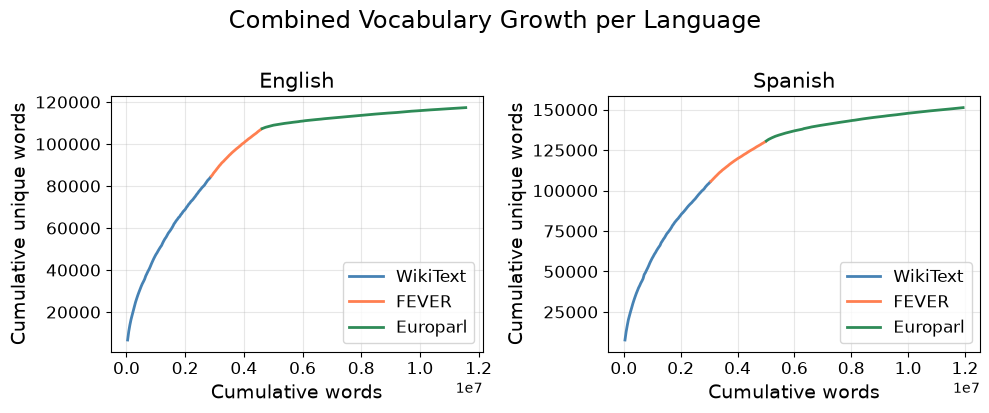

Saved: vocabulary_growth.png


In [11]:
# Plot combined growth curve with dataset boundaries
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors_ds = {'wikitext': 'steelblue', 'fever': 'coral', 'europarl': 'seagreen'}

for idx, lang in enumerate(['english', 'spanish']):
    gc = growth[lang]['growth_curve']
    
    # Group points by dataset for coloring
    for ds in order:
        ds_points = [p for p in gc if p['dataset'] == ds]
        if ds_points:
            words = [p['tokens'] for p in ds_points]
            types = [p['types'] for p in ds_points]
            axes[idx].plot(words, types, color=colors_ds[ds], linewidth=2, label=LABELS[ds])
    
    axes[idx].set_title(lang.capitalize(), fontsize=15)
    axes[idx].set_xlabel('Cumulative words', fontsize=14)
    axes[idx].set_ylabel('Cumulative unique words', fontsize=14)
    axes[idx].tick_params(labelsize=12)
    axes[idx].legend(fontsize=12)
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Combined Vocabulary Growth per Language', fontsize=17, y=1.02)
plt.tight_layout()
fig.savefig(GRAPHICS_DIR / 'vocabulary_growth.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("Saved: vocabulary_growth.png")

### 8.5 Combined Classification Distribution

Total entries: 12,003
Total categories: 53


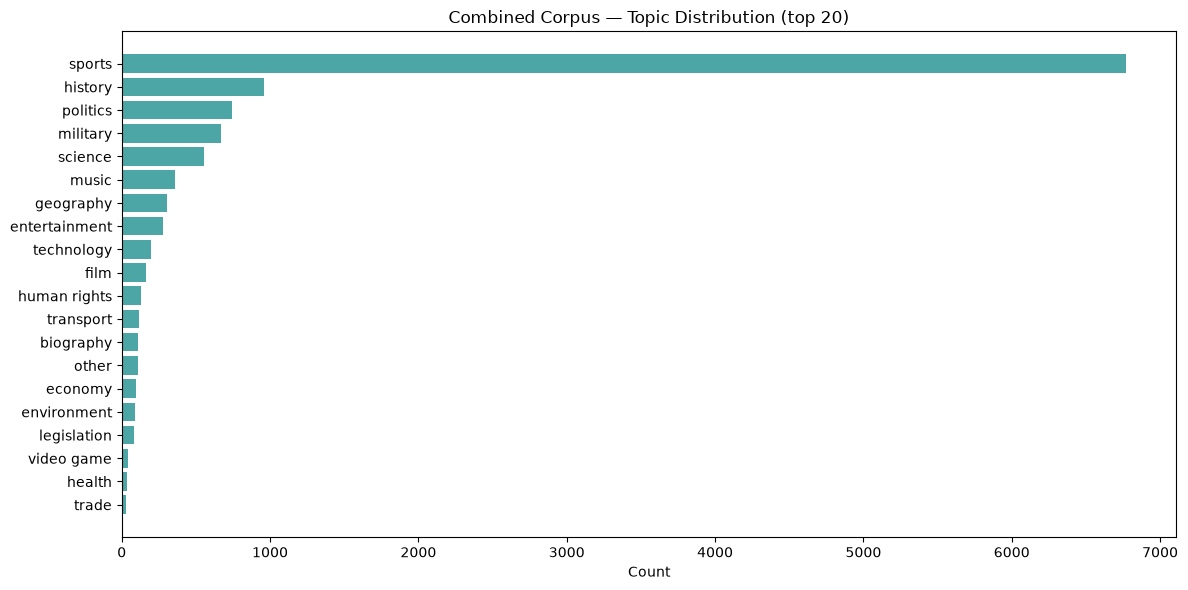


Top 15 categories with per-dataset breakdown:


,Category,Total,WikiText,FEVER,Europarl
0,sports,6771,96,6675,0
1,history,958,284,674,0
2,politics,741,18,240,483
3,military,666,0,666,0
4,science,553,107,446,0
5,music,360,1,359,0
6,geography,303,0,303,0
7,entertainment,279,260,19,0
8,technology,200,23,172,5
9,film,163,0,163,0


In [24]:
classification = compute_combined_classification(data)

print(f"Total entries: {classification['total_entries']:,}")
print(f"Total categories: {classification['total_categories']}")

# Combined distribution plot
fig, ax = plt.subplots(1, 1, figsize=(12, 6))
cats = list(classification['combined'].keys())[:20]  # Top 20
counts = [classification['combined'][c] for c in cats]
ax.barh(cats, counts, color='teal', alpha=0.7)
ax.set_title('Combined Corpus — Topic Distribution (top 20)')
ax.set_xlabel('Count')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Per-dataset contribution to each category
print("\nTop 15 categories with per-dataset breakdown:")
rows = []
for cat in cats[:15]:
    row = {'Category': cat, 'Total': classification['combined'][cat]}
    for ds in DATASETS:
        row[LABELS[ds]] = classification['per_dataset'].get(ds, {}).get(cat, 0)
    rows.append(row)
pd.DataFrame(rows)

### 8.6 Save Combined Metrics to JSON

In [25]:
combined_result = {
    'metadata': {
        'datasets': DATASETS,
        'total_entries': sum(data[ds]['total_entries'] for ds in DATASETS),
        'generated_at': datetime.now().isoformat(),
    },
    'combined_totals': totals,
    'vocabulary_overlap': overlap,
    'cross_dataset_duplicates': cross_dupes,
    'combined_growth_curve': growth,
    'combined_classification': classification,
}

timestamp = datetime.now().strftime('%y%m%d_%H%M%S')
combined_path = output_dir / f'metrics_combined_{timestamp}.json'
with open(combined_path, 'w', encoding='utf-8') as f:
    json.dump(combined_result, f, ensure_ascii=False, indent=2)

size_mb = combined_path.stat().st_size / (1024 * 1024)
print(f"Saved: {combined_path.name} ({size_mb:.1f} MB)")

Saved: metrics_combined_260907_135630.json (0.1 MB)


---
## 9. Article Figures

Generate publication-quality PNG figures for the article (saved to `figures/`).

In [26]:
from pathlib import Path

GRAPHICS_DIR = Path('../figures')
GRAPHICS_DIR.mkdir(parents=True, exist_ok=True)

# Common style for article figures
plt.rcParams.update({
    'figure.dpi': 300,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 9,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1,
})

print(f"Saving figures to: {GRAPHICS_DIR.resolve()}")

Saving figures to: /mnt/c/Users/Mario/Documents/desarrollo/tec/inrae/claude/itzae/CorpusCienciaDeFrontera/translation/article_sections/graphics


### 9.1 Zipf Distribution (log-log plot)

Shows that word frequency distributions follow Zipf's law in both languages across all datasets.

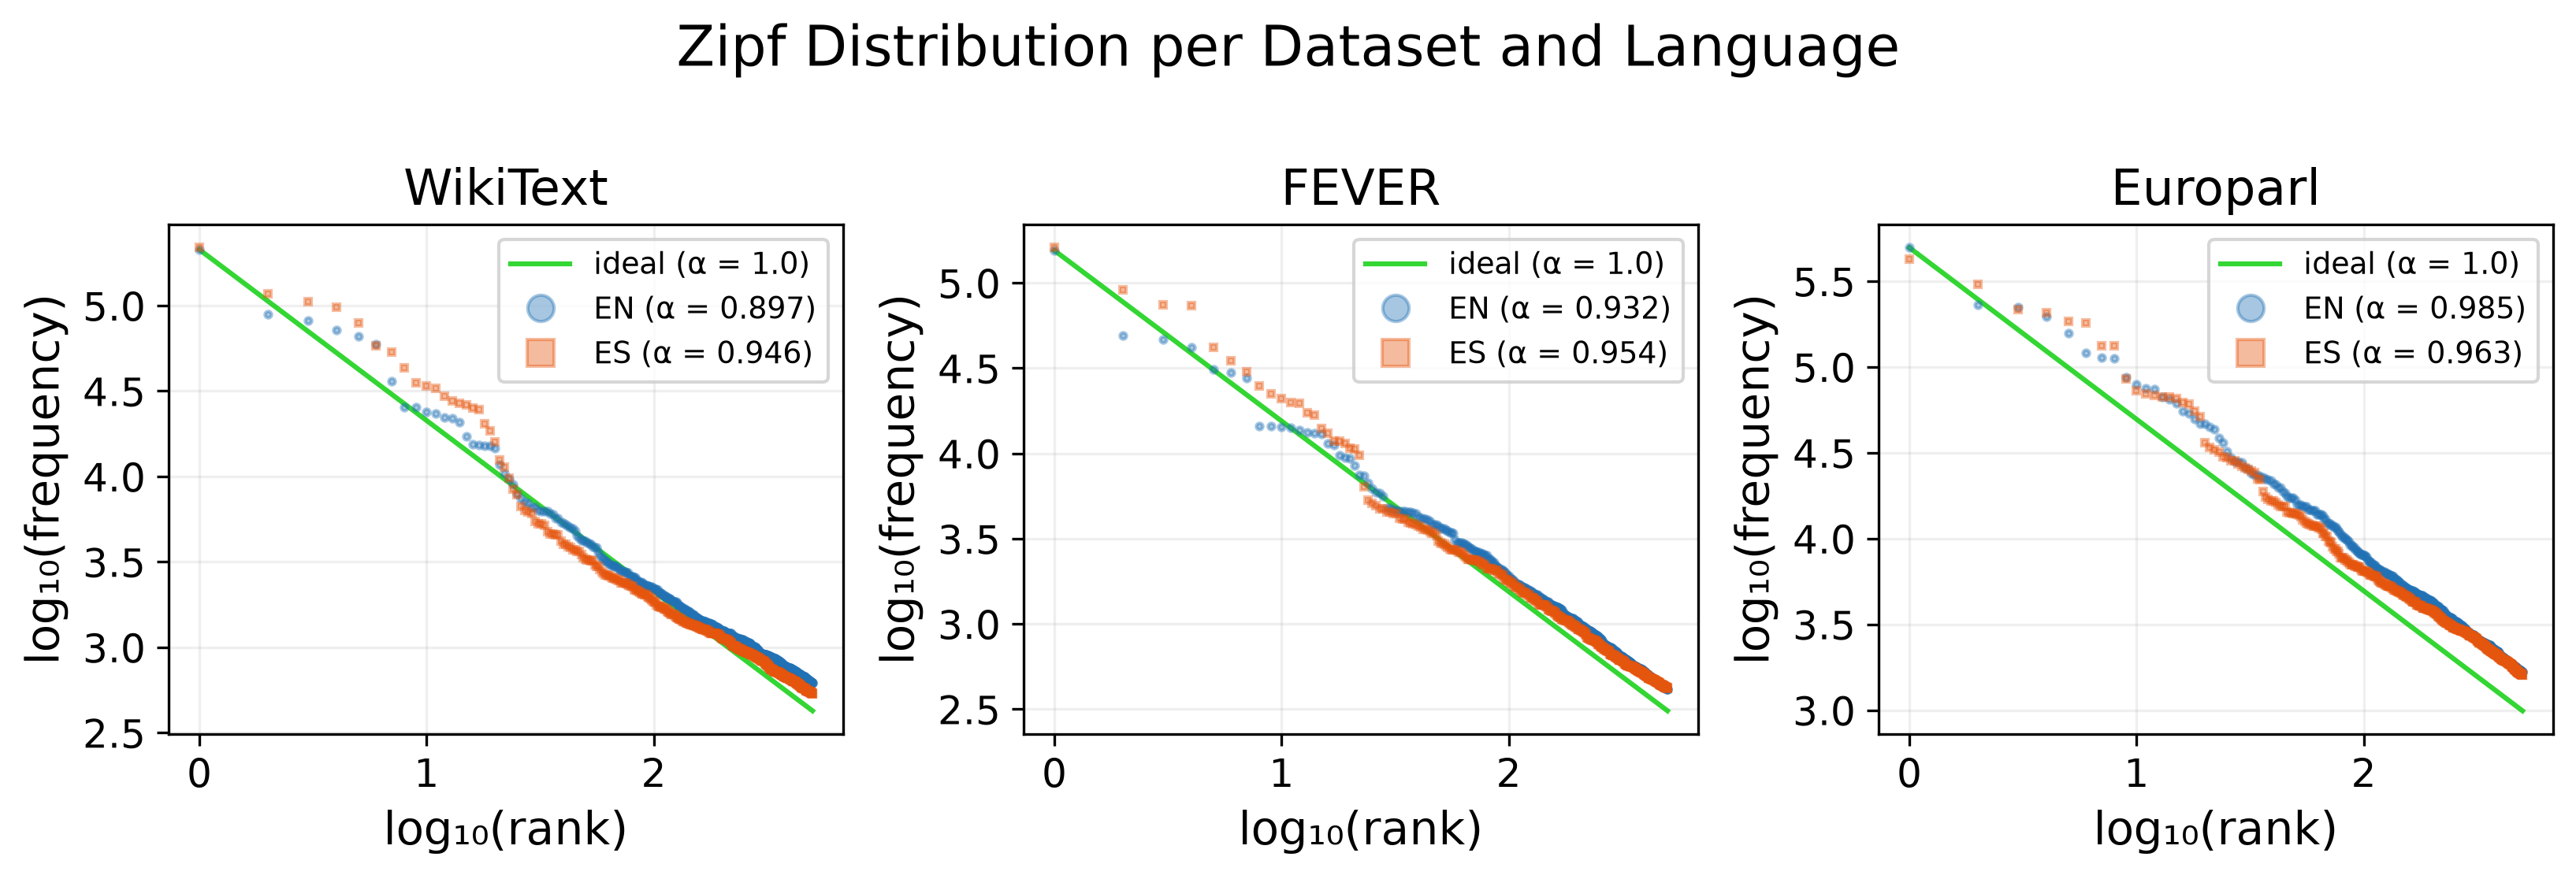

Saved: zipf_distribution.png


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))

for i, ds in enumerate(DATASETS):
    # Get range for reference line
    all_ranks = []
    for lang in ['en', 'es']:
        z = frequency[ds][lang]['zipf_distribution']
        all_ranks.extend([p['log_rank'] for p in z])
    r_min, r_max = min(all_ranks), max(all_ranks)

    # Reference line: perfect Zipf (slope = -1), bright green
    freq_at_1 = frequency[ds]['en']['zipf_distribution'][0]['log_freq']
    ref_x = np.linspace(r_min, r_max, 100)
    ref_y = freq_at_1 - (ref_x - r_min)
    axes[i].plot(ref_x, ref_y, '-', color='#00cc00', linewidth=1.5, alpha=0.8, label='ideal (α = 1.0)')

    # Plot data
    for lang, color, marker in [('en', '#2171b5', 'o'), ('es', '#e6550d', 's')]:
        z = frequency[ds][lang]['zipf_distribution']
        ranks = [p['log_rank'] for p in z]
        freqs = [p['log_freq'] for p in z]
        alpha = frequency[ds][lang]['zipf_exponent']
        axes[i].plot(ranks, freqs, marker, color=color, alpha=0.4, markersize=2,
                     label=f'{lang.upper()} (α = {alpha:.3f})')
    axes[i].set_title(LABELS[ds], fontsize=15)
    axes[i].set_xlabel('log₁₀(rank)', fontsize=14)
    axes[i].set_ylabel('log₁₀(frequency)', fontsize=14)
    axes[i].tick_params(labelsize=12)
    axes[i].legend(loc='upper right', fontsize=9, markerscale=4)
    axes[i].grid(True, alpha=0.2)

plt.suptitle('Zipf Distribution per Dataset and Language', fontsize=17, y=1.02)
plt.tight_layout()
fig.savefig(GRAPHICS_DIR / 'zipf_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("Saved: zipf_distribution.png")

### 9.2 Expansion Ratio Distribution

Shows the character expansion ratio (ES/EN) per dataset, highlighting truncation outliers.

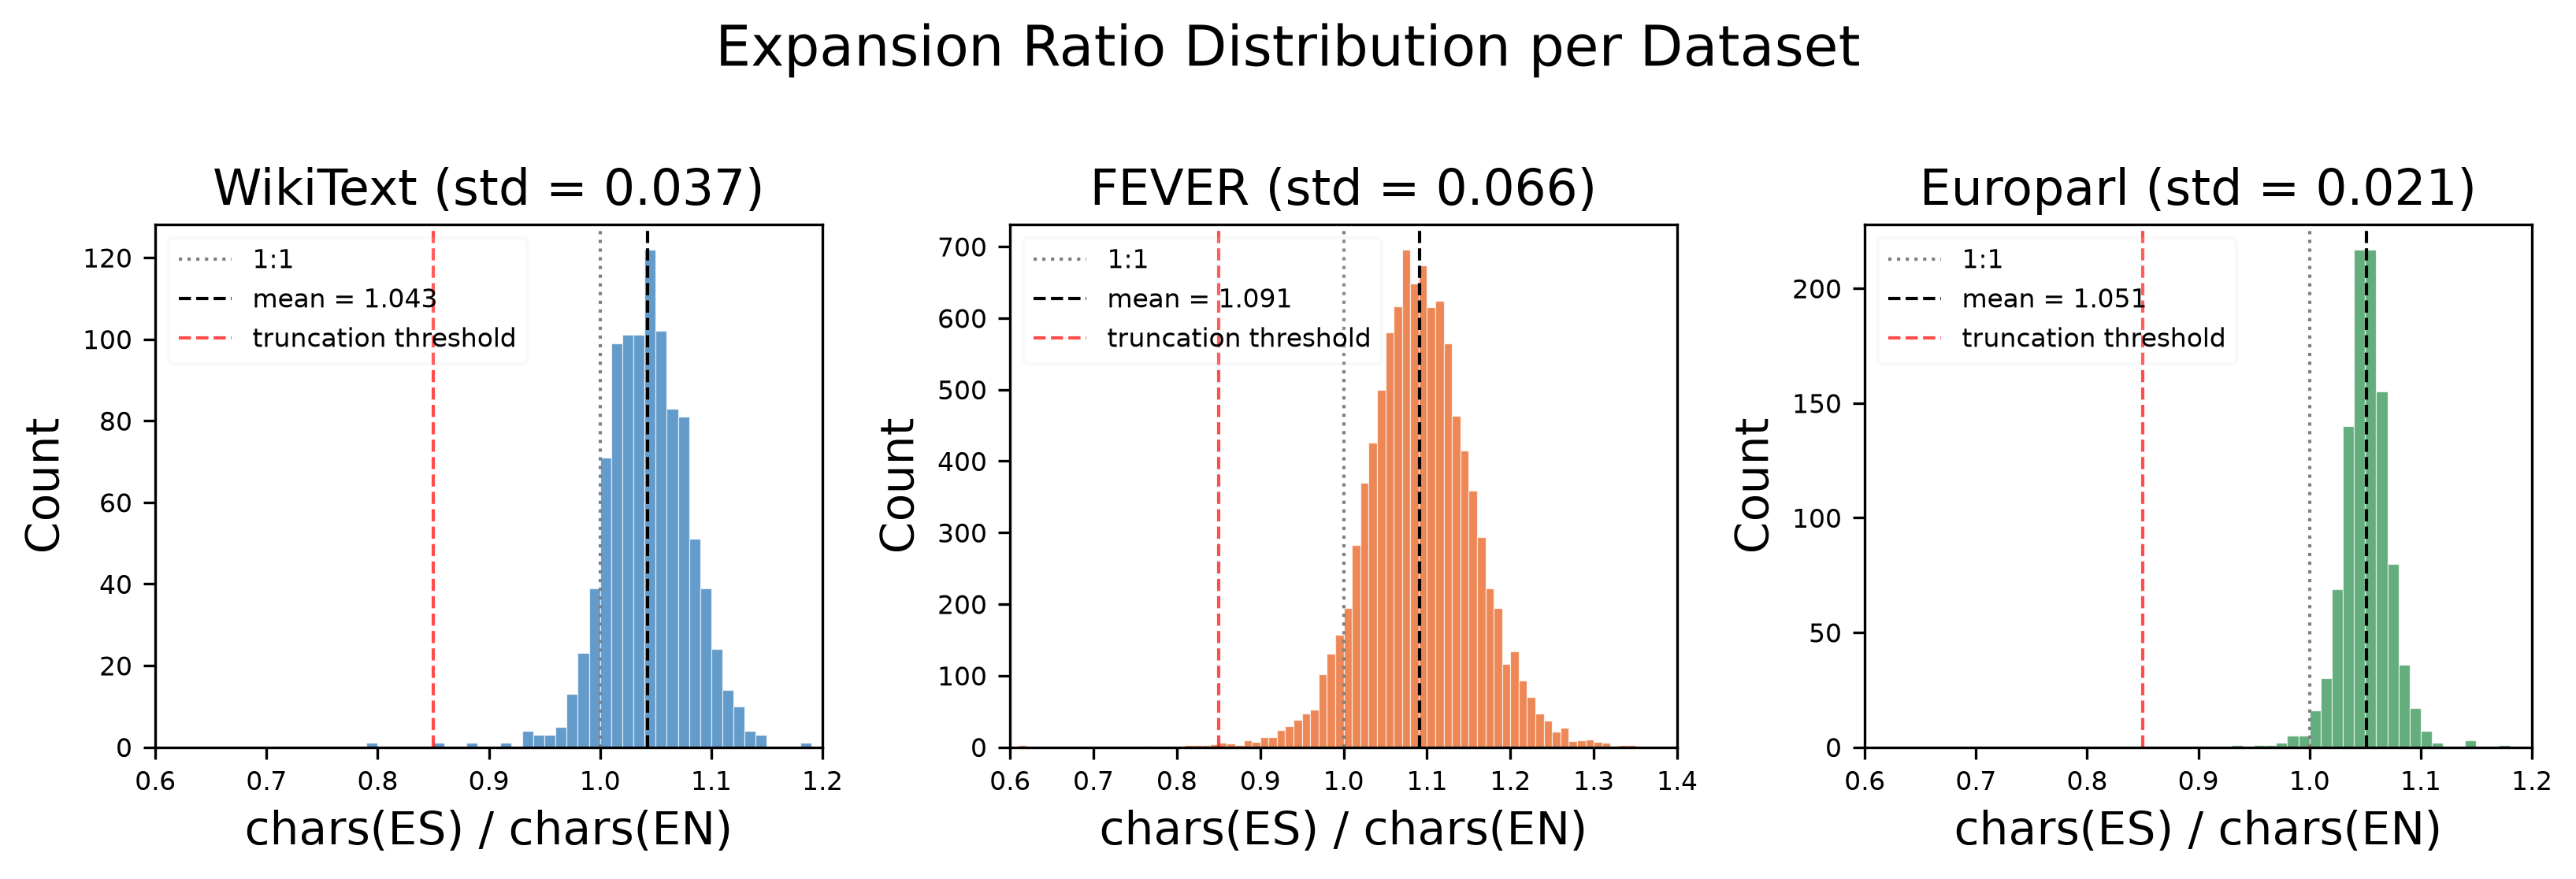

Saved: expansion_ratio_distribution.png


In [43]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
colors_ds = {'wikitext': '#2171b5', 'fever': '#e6550d', 'europarl': '#238b45'}
xmax_ds   = {'wikitext': 1.2,       'fever': 1.4,       'europarl': 1.2}

for i, ds in enumerate(DATASETS):
    ratios = quality[ds]['expansion_ratio_en_es']['distribution']
    mean_r = quality[ds]['expansion_ratio_en_es']['mean']
    std_r = quality[ds]['expansion_ratio_en_es']['std']
    
    axes[i].hist(ratios, bins=np.arange(0.6, 1.41, 0.01), color=colors_ds[ds], alpha=0.7, edgecolor='white', linewidth=0.3)
    axes[i].axvline(x=1.0, color='gray', linestyle=':', linewidth=1, label='1:1')
    axes[i].axvline(x=mean_r, color='black', linestyle='--', linewidth=1,
                    label=f'mean = {mean_r:.3f}')
    axes[i].axvline(x=0.85, color='red', linestyle='--', linewidth=1, alpha=0.7,
                    label='truncation threshold')
    axes[i].set_title(f'{LABELS[ds]} (std = {std_r:.3f})', fontsize=15)
    axes[i].set_xlabel('chars(ES) / chars(EN)', fontsize=14)
    axes[i].set_ylabel('Count', fontsize=14)
    axes[i].tick_params(labelsize=8)
    axes[i].set_xlim(0.6, xmax_ds[ds])
    axes[i].legend(loc='upper left', fontsize=8, framealpha=0.1)

plt.suptitle('Expansion Ratio Distribution per Dataset', fontsize=17, y=1.02)
plt.tight_layout()
fig.savefig(GRAPHICS_DIR / 'expansion_ratio_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("Saved: expansion_ratio_distribution.png")

### 9.3 Overall Evaluation Score Distribution

Shows the distribution of Stage 5 overall quality scores per dataset (from pipeline JSON).

  WikiText: 995 scores loaded
  FEVER: 9,994 scores loaded
  Europarl: 1,003 scores loaded


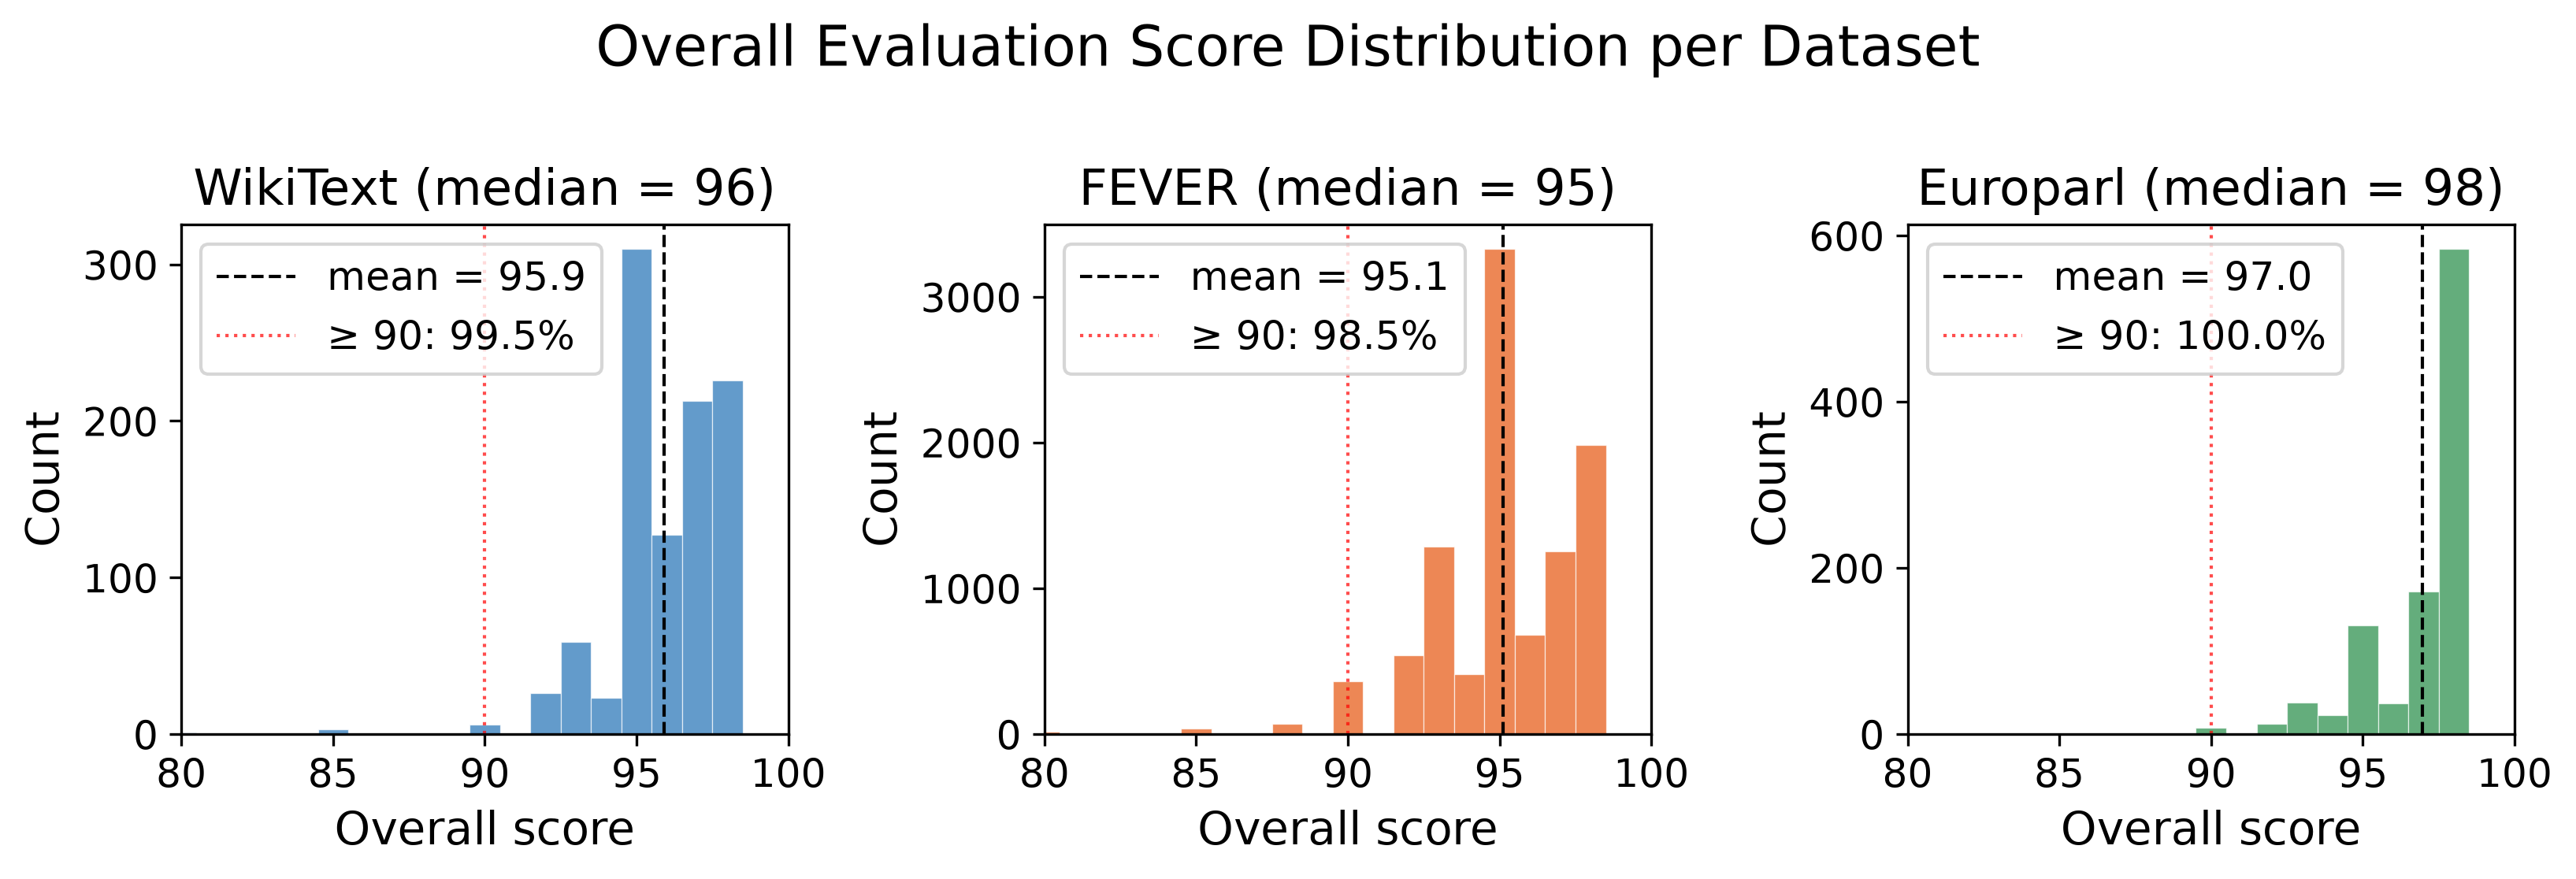

Saved: evaluation_score_distribution.png


In [37]:
# Load pipeline JSONs for evaluation scores
PIPELINE_FILES = {
    'wikitext': Path('../output/wikitext/wikitext-103-raw.wiki.train.selected_1000_pipeline_260620_235838.json'),
    'fever':    Path('../output/FEVER/fever_selected_pipeline_260712_212751.json'),
    'europarl': Path('../output/Europarl/selected_pipeline_260710_084528.json'),
}

pipeline_scores = {}
for ds, path in PIPELINE_FILES.items():
    with open(path, 'r', encoding='utf-8') as f:
        pipe = json.load(f)
    scores = []
    for entry in pipe['pipeline']:
        ev = entry.get('evaluation')
        if ev and isinstance(ev, dict) and 'overall_score' in ev:
            scores.append(ev['overall_score'])
    pipeline_scores[ds] = scores
    print(f"  {LABELS[ds]}: {len(scores):,} scores loaded")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
colors_ds = {'wikitext': '#2171b5', 'fever': '#e6550d', 'europarl': '#238b45'}

for i, ds in enumerate(DATASETS):
    scores = pipeline_scores[ds]
    mean_s = np.mean(scores)
    median_s = np.median(scores)
    pct_above_90 = sum(1 for s in scores if s >= 90) / len(scores) * 100
    
    axes[i].hist(scores, bins=np.arange(79.5, 99.5, 1), color=colors_ds[ds], alpha=0.7, edgecolor='white', linewidth=0.3)
    axes[i].axvline(x=mean_s, color='black', linestyle='--', linewidth=1,
                    label=f'mean = {mean_s:.1f}')
    axes[i].axvline(x=90, color='red', linestyle=':', linewidth=1, alpha=0.7,
                    label=f'≥ 90: {pct_above_90:.1f}%')
    axes[i].set_title(f'{LABELS[ds]} (median = {median_s:.0f})', fontsize=15)
    axes[i].set_xlabel('Overall score', fontsize=14)
    axes[i].set_ylabel('Count', fontsize=14)
    axes[i].tick_params(labelsize=12)
    axes[i].set_xlim(80, 100)
    axes[i].legend(fontsize=12)

plt.suptitle('Overall Evaluation Score Distribution per Dataset', fontsize=17, y=1.02)
plt.tight_layout()
fig.savefig(GRAPHICS_DIR / 'evaluation_score_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("Saved: evaluation_score_distribution.png")

### 9.4 Reviewer Critique Scores (Box Plot)

Shows the distribution of reviewer critique scores per translation model, explaining why Mistral Large is chosen as base despite similar means.

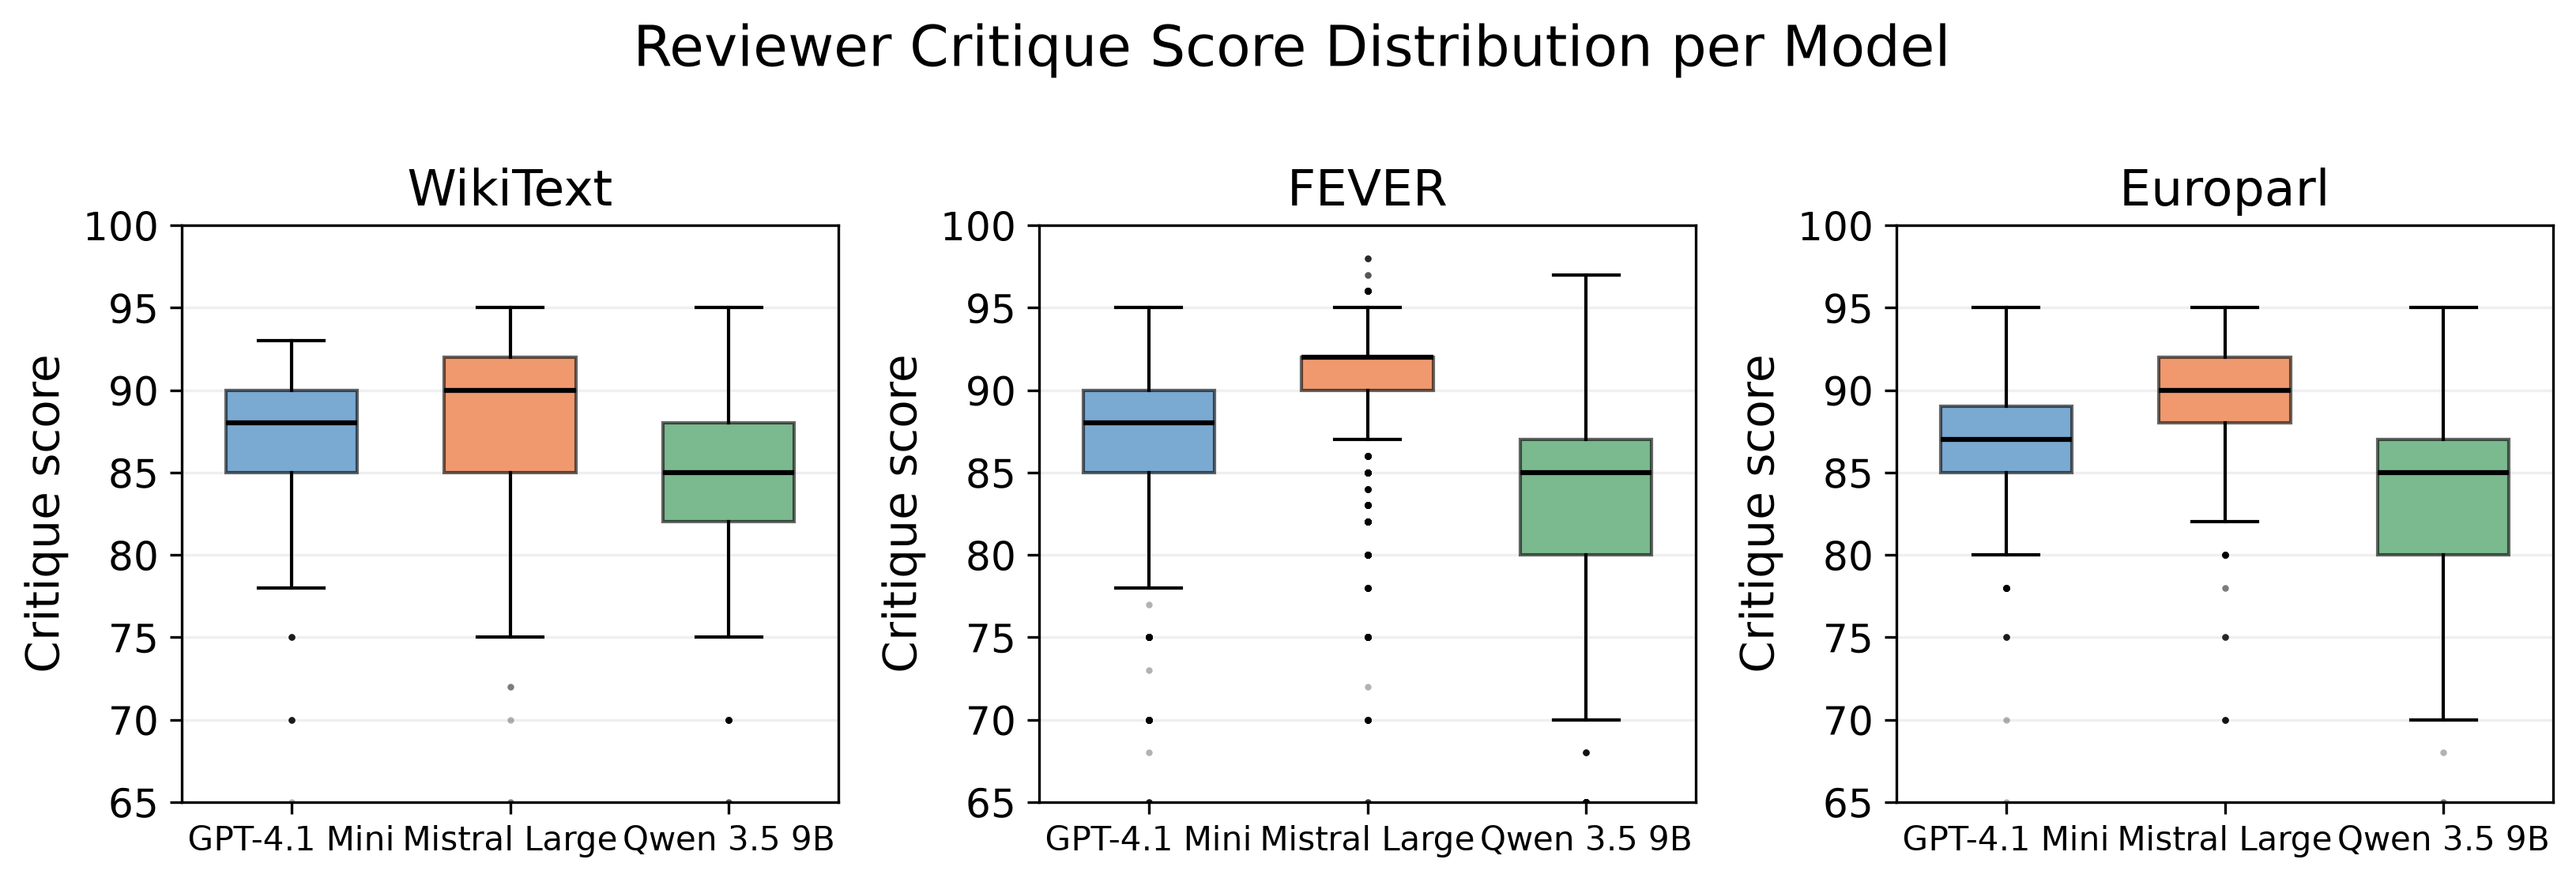

Saved: critique_scores_boxplot.png


In [38]:
from collections import defaultdict
import re as re_mod

# Extract critique scores per model per dataset from pipeline JSONs
model_short = {
    'dataset-frontierscience-gpt41mini': 'GPT-4.1 Mini',
    'dataset-frontierscience-mistral-large': 'Mistral Large',
    '9b': 'Qwen 3.5 9B',
}

all_scores = defaultdict(lambda: defaultdict(list))  # {dataset: {model: [scores]}}

for ds, path in PIPELINE_FILES.items():
    with open(path, 'r', encoding='utf-8') as f:
        pipe = json.load(f)
    for entry in pipe['pipeline']:
        review = entry.get('review')
        if not review or not review.get('critique'):
            continue
        critique = review['critique']
        if isinstance(critique, dict) and 'candidates_analysis' in critique:
            for ca in critique['candidates_analysis']:
                model = ca.get('model', '?')
                short = model.split(':')[-1] if ':' in model else model
                score = ca.get('score')
                if isinstance(score, (int, float)) and short in model_short:
                    all_scores[ds][model_short[short]].append(score)

# Plot: one box plot per dataset, 3 models side by side
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
model_order = ['GPT-4.1 Mini', 'Mistral Large', 'Qwen 3.5 9B']
colors_model = ['#2171b5', '#e6550d', '#238b45']

for i, ds in enumerate(DATASETS):
    box_data = [all_scores[ds][m] for m in model_order]
    bp = axes[i].boxplot(box_data, patch_artist=True,
                         widths=0.6, showfliers=True,
                         flierprops=dict(marker='.', markersize=2, alpha=0.3))
    axes[i].set_xticklabels(model_order, fontsize=10)
    for patch, color in zip(bp['boxes'], colors_model):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    for median in bp['medians']:
        median.set_color('black')
        median.set_linewidth(1.5)
    axes[i].set_title(LABELS[ds], fontsize=15)
    axes[i].set_ylabel('Critique score', fontsize=14)
    axes[i].tick_params(axis='y', labelsize=12)
    axes[i].set_ylim(65, 100)
    axes[i].grid(True, alpha=0.2, axis='y')

plt.suptitle('Reviewer Critique Score Distribution per Model', fontsize=17, y=1.02)
plt.tight_layout()
fig.savefig(GRAPHICS_DIR / 'critique_scores_boxplot.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("Saved: critique_scores_boxplot.png")